In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os 
from sklearn.linear_model import LinearRegression

In [6]:
df = pd.read_csv(r'C:\Users\jefferson.faria\Documents\GitHub\ic-2025\ETL\data_processed\data_samples_processed.csv')
data = df.values

In [8]:
output_dir = "./ETL/data_processed/"
output_path = os.path.join(output_dir, "data_samples_correction_msc.csv")

In [42]:
espectro_referencia = np.mean(data, axis = 0).reshape(-1,1)
dados_corrigidos = np.zeros_like(data)
for i in range(data.shape[0]):
    sample = data[i, :].reshape(-1, 1)
    
    model = LinearRegression().fit(espectro_referencia, sample)
    a = model.coef_[0][0]
    b = model.intercept_[0]
    
    corrected_sample = (data[i, :] - b) / a
    dados_corrigidos[i, :] = corrected_sample

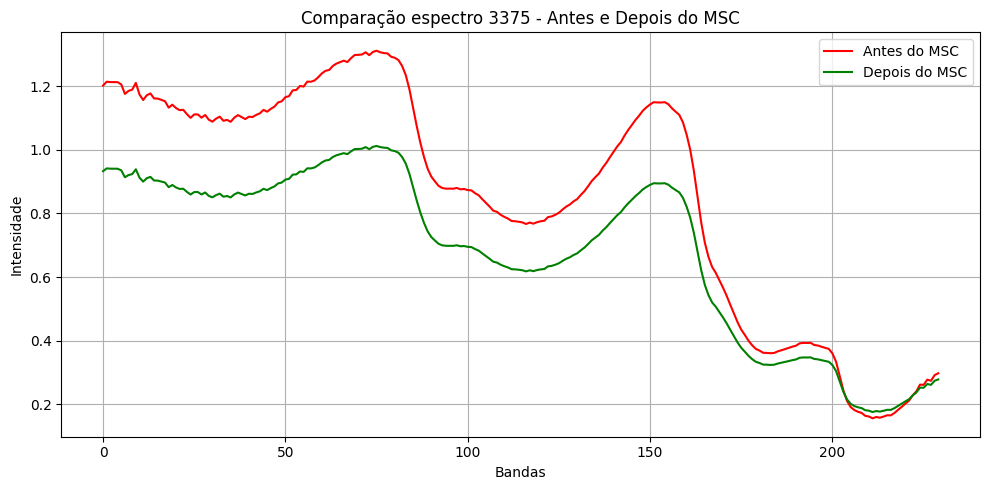

In [45]:
idx = np.random.randint(0, data.shape[0])
plt.figure(figsize=(10, 5))
plt.plot(data[idx], label="Antes do MSC", color="red", linewidth=1.5)
plt.plot(dados_corrigidos[idx], label="Depois do MSC", color="green", linewidth=1.5)
plt.title(f"Comparação espectro {idx} - Antes e Depois do MSC")
plt.xlabel("Bandas")
plt.ylabel("Intensidade")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()